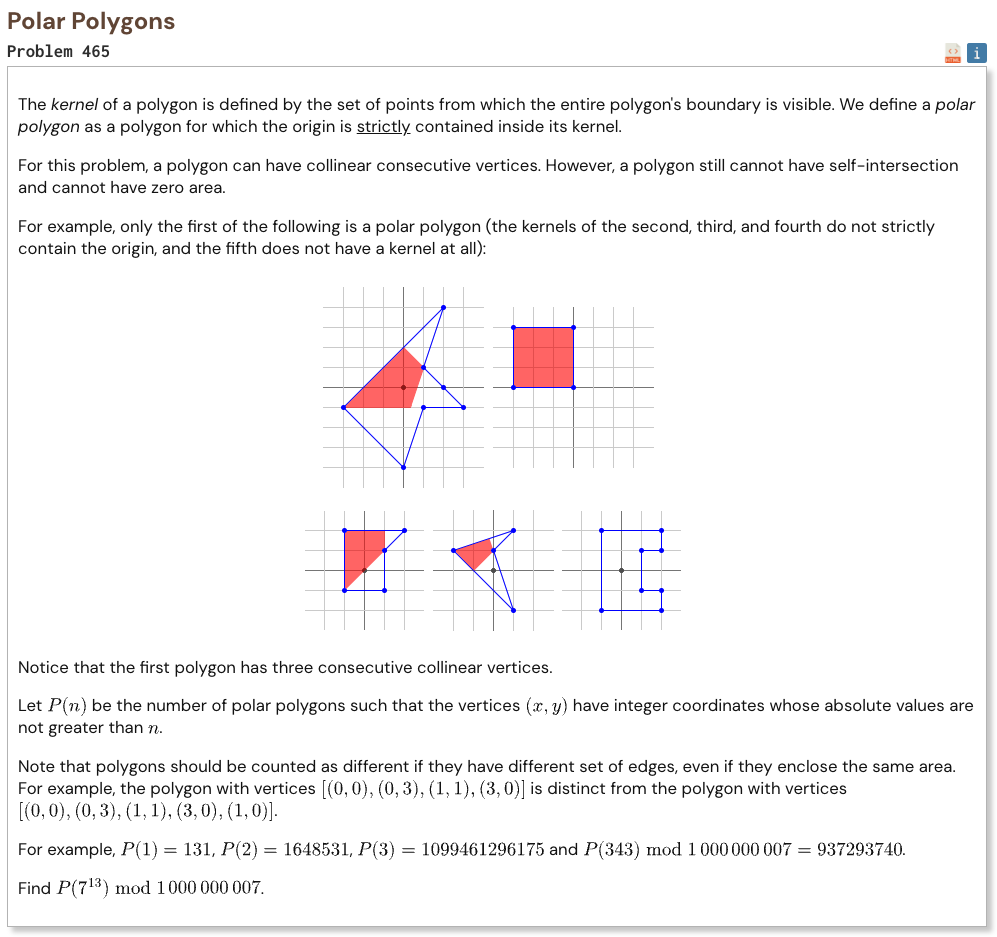

## Initial approach

-   group all nonzero lattice points by their direction from the origin
-   each primitive direction can contribute one vertex chosen from several points on the same ray
-   pair every direction with its opposite direction and count these pairs using Euler's totient function
-   group square shells that have the same number of available lattice points so huge ranges can be processed together
-   use a memoized summatory totient function because the target size is far too large for a direct sieve
-   first count all possible ray selections, then subtract selections that fit inside a semicircle and therefore do not contain the origin properly
-   combine the product and two weighted sums to get the number of valid polar polygons modulo one billion and seven
-   use array to store the large totient tables with much less memory than normal Python integer lists

In [1]:
%%time

from array import array

MOD = 1_000_000_007
N = 7**13
LIMIT = 10_000_000

phi = array("I", range(LIMIT + 1))
primes = array("I")

for i in range(2, LIMIT + 1):
    if phi[i] == i:
        primes.append(i)
        phi[i] = i - 1

    for p in primes:
        value = i * p

        if value > LIMIT:
            break

        if i % p == 0:
            phi[value] = phi[i] * p
            break

        phi[value] = phi[i] * (p - 1)

prefix = array("Q", [0]) * (LIMIT + 1)

for i in range(1, LIMIT + 1):
    prefix[i] = prefix[i - 1] + phi[i]

memo = {}

def totient_sum(n):
    if n <= LIMIT:
        return prefix[n]

    if n in memo:
        return memo[n]

    result = n * (n + 1) // 2
    left = 2

    while left <= n:
        q = n // left
        right = n // q

        result -= (right - left + 1) * totient_sum(q)
        left = right + 1

    memo[n] = result
    return result

product = 1
sum_weights = 0
sum_squares = 0

left = 1

while left <= N:
    weight = N // left
    right = N // weight

    directions = totient_sum(right) - totient_sum(left - 1)
    pairs = 4 * directions

    product *= pow(weight + 1, pairs, MOD)
    product %= MOD

    pairs_mod = pairs % MOD
    weight_mod = weight % MOD

    sum_weights += pairs_mod * weight_mod
    sum_weights %= MOD

    sum_squares += pairs_mod * weight_mod * weight_mod
    sum_squares %= MOD

    left = right + 1

result = (
    product * product
    - 1
    - 2 * product * sum_weights
    + sum_squares
) % MOD

print("Result:", result)

Result: 585965659
CPU times: user 19.7 s, sys: 81.6 ms, total: 19.8 s
Wall time: 20 s
